# F1 championship prediction with fastf1

Can we predict the **final championship standings** before the season ends - who wins the title, and what the table looks like when the last race has been run?

This notebook builds a complete machine-learning pipeline for exactly that:

1. **Collect** - race results for every completed round of the target season (the same `data/season_<year>.csv` the race notebook writes), plus every **complete earlier season bundled in `data/`** - the training pool.
2. **Explore** - how early in a season is the champion effectively decided, and how good is a naive run-rate extrapolation of the current table?
3. **Engineer features** - one *snapshot* row per entrant per round: points so far, scoring rates, standings position, gap to the leader, form and reliability - the championship state after each round, exactly what is known at forecast time.
4. **Model** - two histogram gradient boosters: a *remaining-points* model (final points minus points so far, anchored at the current table) and a *direct* model (absolute final points), both trained **across seasons** - a mid-season snapshot cannot know its own season's final points, so the targets come from complete earlier seasons.
5. **Backtest** - leave-one-season-out: every complete bundled season is forecast after each of its rounds, each time trained only on earlier seasons, against a naive run-rate baseline.
6. **Predict** - the projected final drivers' (or constructors') table, champion pick and title margins as of the last completed round.

Requirements: `pip install fastf1 pandas numpy scikit-learn matplotlib`

A command-line version of the same pipeline lives in `predict_championship.py`.


## 1. Setup

- `fastf1` stores downloaded timing data in a local `cache/` folder, so repeated runs are fast and don't re-hit the F1 API.
- The championship pipeline reads the **race** pipeline's season files (`data/season_<year>.csv`) and refreshes them incrementally, exactly like the race notebook: after each new race you re-run the notebook and only the missing rounds are downloaded.
- `SEASON` is the season whose final standings are projected (the 2026 season is in progress, so that is the default; a complete season switches the notebook to scored review mode).
- `CHAMPIONSHIP` picks the drivers' (`"drivers"`) or constructors' (`"constructors"`) title.
- `SNAPSHOT_ROUND` projects the standings as of that completed round (`None` = the last completed round).
- `MODEL_PROFILE` selects the model profile: `"fast"` trains with the project's fixed hyperparameters, `"optimized"` searches for better ones before every fit (slower to run, usually lower error - see section 5).
- The fastf1 log level is raised so download chatter doesn't drown the notebook output.


In [1]:
import re
import warnings
from datetime import datetime, timedelta, timezone
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import fastf1
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CACHE_DIR = BASE_DIR / "cache"
DATA_DIR = BASE_DIR / "data"
CACHE_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)

fastf1.Cache.enable_cache(str(CACHE_DIR))
fastf1.logger.set_log_level("WARNING")

SEASON = 2026                  # season whose final standings are projected
CHAMPIONSHIP = "drivers"       # "drivers" or "constructors"
SNAPSHOT_ROUND = None          # None = the season's last completed round
MIN_TRAIN_ROUNDS = 5           # completed rounds before the first forecast
MODEL_PROFILE = "fast"         # "fast" or "optimized" (see section 5)
STINT_WINDOW = 5
STINT_MIN_LAPS = 3
COMPLETION_BUFFER = timedelta(hours=3)

PRACTICE_COLS = ["fp_race_pace_delta", "fp_best_delta", "fp_laps"]
SPRINT_COLS = ["sprint_quali_pos", "sprint_finish", "sprint_gain"]

RAW_COLUMNS = [
    "round",
    "event",
    "driver_number",
    "driver",
    "team",
    "grid",
    "quali_time",
    "finish",
    "points",
    "status",
] + PRACTICE_COLS + SPRINT_COLS

# Championship points are the race-session points plus the sprint points
# implied by the stored sprint finishing positions: 3-2-1 in 2021,
# 8-7-6-5-4-3-2-1 since 2022, none before 2021 (positions outside the
# scheme score nothing).
SPRINT_POINTS_2021 = {1: 3.0, 2: 2.0, 3: 1.0}
SPRINT_POINTS = {pos: float(9 - pos) for pos in range(1, 9)}

DRIVER_FEATURES = [
    "rounds_done",
    "rounds_remaining",
    "points_so_far",
    "points_per_round",
    "points_rate_projection",
    "points_last3_rate",
    "standings_pos",
    "gap_to_leader",
    "leader_points",
    "finish_avg",
    "finish_form3",
    "best_finish",
    "quali_delta_avg",
    "quali_delta_form3",
    "wins",
    "podiums",
    "dnf_count",
    "dnf_rate",
    "team_points_so_far",
    "team_points_per_round",
    "team_points_last3_rate",
    "team_finish_avg",
    "team_dnf_rate",
    "team_id",
    "driver_id",
]

TEAM_FEATURES = [
    "rounds_done",
    "rounds_remaining",
    "points_so_far",
    "points_per_round",
    "points_rate_projection",
    "points_last3_rate",
    "standings_pos",
    "gap_to_leader",
    "leader_points",
    "finish_avg",
    "best_finish",
    "quali_delta_avg",
    "podiums",
    "dnf_count",
    "dnf_rate",
    "team_id",
]

CHAMPIONSHIPS = {
    "drivers": {
        "label": "Drivers' championship",
        "entrant": "driver",
        "tiebreak": "driver_number",
        "features": DRIVER_FEATURES,
    },
    "constructors": {
        "label": "Constructors' championship",
        "entrant": "team",
        "tiebreak": "team",
        "features": TEAM_FEATURES,
    },
}

plt.rcParams.update({
    "figure.figsize": (11, 5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "axes.titlesize": 12,
})

print("fastf1", fastf1.__version__, "| season", SEASON,
      "| championship", CHAMPIONSHIP, "| profile", MODEL_PROFILE)


fastf1 3.8.3 | season 2026 | championship drivers | profile fast


## 2. Collecting season data

The forecast needs two kinds of data:

- **The target season** - race results for every completed round, fetched exactly like the race notebook (qualifying delta, grid, finish, points, status, practice analysis and sprint results), cached in `data/season_<year>.csv`. Only completed rounds count: a snapshot of the championship exists only after a round has been run.
- **The training pool** - every *complete* earlier season bundled in `data/` (`season_2018.csv` ... `season_2025.csv`), read straight from disk. A mid-season snapshot cannot know its own season's final standings, so training targets must come from seasons that are over - the models learn, across seasons, what a championship table at round *N* says about the final one.

Championship points here are the race-session points **plus the sprint points** implied by the stored sprint finishing positions (3-2-1 in 2021, 8-7-...-1 since 2022, none before 2021) - the derivation reproduces the official standings of every bundled season.

The snapshot builder below turns each season into one row per (entrant, round): the championship state **after** that round - points so far, scoring rates, standings position, gap to the leader, win/podium/DNF counts, team-level form. Unlike the race notebook's "before the race" features these are *inclusive* of the round itself, because a snapshot at the last completed round is exactly the live forecasting task.


In [2]:
def utc_now():
    return pd.Timestamp(datetime.now(timezone.utc)).replace(tzinfo=None)


def session_utc(row, name):
    for i in range(1, 6):
        if row.get(f"Session{i}") == name:
            value = row.get(f"Session{i}DateUtc")
            if pd.isna(value):
                return None
            return pd.Timestamp(value)
    return None


def completed_rounds(schedule):
    # (round_number, event_name) pairs whose race started
    # >COMPLETION_BUFFER ago - a race in progress never counts
    now = utc_now()
    rounds = []
    for _, ev in schedule.iterrows():
        race_utc = session_utc(ev, "Race")
        if race_utc is not None and race_utc < now - COMPLETION_BUFFER:
            rounds.append((int(ev["RoundNumber"]), str(ev["EventName"])))
    return rounds


def best_quali_seconds(qres, num):
    if num not in qres.index:
        return np.nan
    times = []
    for col in ("Q1", "Q2", "Q3"):
        if col in qres.columns:
            value = qres.at[num, col]
            if pd.notna(value):
                times.append(pd.Timedelta(value).total_seconds())
    return min(times) if times else np.nan


def pole_seconds(qres):
    times = [best_quali_seconds(qres, num) for num in qres.index]
    times = [t for t in times if not np.isnan(t)]
    return min(times) if times else np.nan


def result_row(res, num, round_number, event_name):
    row = res.loc[num]
    grid = row["GridPosition"]
    grid = float(grid) if pd.notna(grid) and grid > 0 else np.nan
    finish = row["Position"]
    finish = float(finish) if pd.notna(finish) else np.nan
    points = row["Points"]
    points = float(points) if pd.notna(points) else 0.0
    return {
        "round": round_number,
        "event": event_name,
        "driver_number": str(num),
        "driver": row["Abbreviation"],
        "team": row["TeamName"],
        "grid": grid,
        "quali_time": np.nan,
        "finish": finish,
        "points": points,
        "status": str(row["Status"]),
    }


def _clean_practice_laps(session):
    laps = session.laps
    if laps is None or laps.empty:
        return pd.DataFrame()
    clean = laps[
        laps["LapTime"].notna()
        & laps["IsAccurate"].fillna(False)
        & laps["PitInTime"].isna()
        & laps["PitOutTime"].isna()
        & (laps["TrackStatus"].astype(str) == "1")
    ][["DriverNumber", "Stint", "LapNumber", "LapTime"]].copy()
    if clean.empty:
        return clean
    clean["DriverNumber"] = clean["DriverNumber"].astype(str)
    clean["seconds"] = clean["LapTime"].dt.total_seconds()
    return clean


def _practice_session_frame(session):
    clean = _clean_practice_laps(session)
    if clean.empty:
        return None
    best_lap = clean.groupby("DriverNumber")["seconds"].min()
    stint_best = {}
    for (num, _), group in clean.groupby(["DriverNumber", "Stint"]):
        if len(group) < STINT_MIN_LAPS:
            continue
        group = group.sort_values("LapNumber")
        pace = group["seconds"].rolling(STINT_WINDOW, min_periods=STINT_MIN_LAPS).mean().min()
        stint_best[num] = min(stint_best.get(num, np.inf), pace)
    if len(stint_best) < 3:
        return None
    stint = pd.Series(stint_best)
    return pd.DataFrame({
        "fp_best_delta": best_lap - best_lap.min(),
        "fp_laps": clean.groupby("DriverNumber").size(),
        "fp_race_pace_delta": stint - stint.min(),
    })


def practice_features(year, round_number):
    frames = []
    for identifier in ("FP1", "FP2", "FP3"):
        try:
            session = fastf1.get_session(year, round_number, identifier)
            session.load(laps=True, telemetry=False, weather=False, messages=False)
            frame = _practice_session_frame(session)
        except Exception:
            frame = None
        if frame is not None:
            frames.append(frame)
    if not frames:
        return pd.DataFrame()
    combined = pd.concat(frames)
    return combined.groupby(level=0).agg(
        fp_race_pace_delta=("fp_race_pace_delta", "min"),
        fp_best_delta=("fp_best_delta", "min"),
        fp_laps=("fp_laps", "sum"),
    )


def sprint_features(year, round_number):
    try:
        sprint = fastf1.get_session(year, round_number, "S")
        sprint.load(laps=False, telemetry=False, weather=False, messages=False)
        results = sprint.results
        if results.empty or results["Position"].isna().all():
            return pd.DataFrame()
    except Exception:
        return pd.DataFrame()
    rows = {}
    for num in results.index:
        row = results.loc[num]
        grid = row["GridPosition"]
        grid = float(grid) if pd.notna(grid) and grid > 0 else np.nan
        finish = row["Position"]
        finish = float(finish) if pd.notna(finish) else np.nan
        rows[str(num)] = {
            "sprint_quali_pos": grid,
            "sprint_finish": finish,
            "sprint_gain": grid - finish if pd.notna(grid) and pd.notna(finish) else np.nan,
        }
    return pd.DataFrame.from_dict(rows, orient="index")


def _merge_weekend_features(frame, year, round_number):
    practice = practice_features(year, round_number)
    if not practice.empty:
        for col in PRACTICE_COLS:
            frame[col] = frame["driver_number"].map(practice[col])
    sprint = sprint_features(year, round_number)
    if not sprint.empty:
        for col in SPRINT_COLS:
            frame[col] = frame["driver_number"].map(sprint[col])
    return frame


def load_completed_round(year, round_number, event_name):
    quali = fastf1.get_session(year, round_number, "Q")
    quali.load(laps=False, telemetry=False, weather=False, messages=False)
    race = fastf1.get_session(year, round_number, "R")
    race.load(laps=False, telemetry=False, weather=False, messages=False)
    qres = quali.results
    rres = race.results
    pole = pole_seconds(qres)
    rows = []
    for num in rres.index:
        entry = result_row(rres, num, round_number, event_name)
        entry["quali_time"] = best_quali_seconds(qres, num)
        rows.append(entry)
    frame = pd.DataFrame(rows, columns=RAW_COLUMNS)
    frame["quali_delta"] = frame["quali_time"] - pole
    return _merge_weekend_features(frame, year, round_number)


In [3]:
def collect_season(year, schedule, refresh=False):
    path = DATA_DIR / f"season_{year}.csv"
    now = utc_now()
    completed = []
    for _, ev in schedule.iterrows():
        race_utc = session_utc(ev, "Race")
        if race_utc is not None and race_utc < now - COMPLETION_BUFFER:
            completed.append((int(ev["RoundNumber"]), str(ev["EventName"])))

    cached = None
    if path.exists() and not refresh:
        candidate = pd.read_csv(path, dtype={"driver_number": str})
        if set(RAW_COLUMNS + ["quali_delta"]).issubset(candidate.columns):
            cached = candidate
        else:
            print("cached season file lacks the newest features, re-downloading")
    have = set(cached["round"].unique()) if cached is not None else set()

    todo = [(rn, name) for rn, name in completed if rn not in have]
    print(f"Season {year}: {len(completed)} completed races ({len(have)} cached, {len(todo)} to fetch)")

    frames = []
    for rn, name in todo:
        try:
            frame = load_completed_round(year, rn, name)
        except Exception as exc:
            print(f"  round {rn:>2} ({name}) skipped: {type(exc).__name__}: {exc}")
            continue
        if frame["finish"].notna().sum() == 0:
            print(f"  round {rn:>2} ({name}) skipped: no classified results yet")
            continue
        print(f"  fetched round {rn:>2}  {name}")
        frames.append(frame)

    if cached is not None:
        frames.insert(0, cached)
    if not frames:
        return pd.DataFrame(columns=RAW_COLUMNS + ["quali_delta"])

    data = pd.concat(frames, ignore_index=True)
    data = data.drop_duplicates(subset=["round", "driver_number"], keep="last")
    data = data.sort_values(["round", "driver_number"]).reset_index(drop=True)
    data.to_csv(path, index=False)
    return data


In [4]:
def sprint_points_map(year):
    return SPRINT_POINTS_2021 if year == 2021 else SPRINT_POINTS


def _finished_like(status):
    # classified as running the full distance - not a retirement:
    # "Finished", the old "+N Lap(s)" classifications, the 2026 "Lapped",
    # and disqualifications (a DSQ completed the race)
    text = str(status)
    return (text == "Finished" or text == "Lapped" or text == "Disqualified"
            or text.startswith("+"))


def bundled_season_years():
    # years with a bundled race-season CSV - the training data source
    years = []
    for path in sorted(DATA_DIR.glob("season_*.csv")):
        try:
            years.append(int(path.stem.split("_")[1]))
        except (IndexError, ValueError):
            continue
    return years


def read_season_csv(year):
    return pd.read_csv(DATA_DIR / f"season_{year}.csv",
                       dtype={"driver_number": str})


def season_is_complete(year, schedule, data):
    # whether the season's whole calendar has run AND is covered by the
    # data (the final round only counts COMPLETION_BUFFER after its race,
    # so a race in progress never produces a complete season)
    rounds_total = int(schedule["RoundNumber"].max())
    if rounds_total not in {rn for rn, _ in completed_rounds(schedule)}:
        return False
    return bool(data["round"].max() >= rounds_total)


def load_training_seasons():
    # {year: (data, rounds_total)} for every complete season bundled in
    # data/ - the pipeline's training data. Incomplete seasons (a season
    # in progress has no known final standings and cannot provide
    # targets) are skipped with a note.
    seasons = {}
    for year in bundled_season_years():
        try:
            season_data = read_season_csv(year)
        except (OSError, ValueError) as exc:
            print(f"season {year}: unreadable ({exc}), skipped")
            continue
        schedule = fastf1.get_event_schedule(year, include_testing=False)
        if season_is_complete(year, schedule, season_data):
            seasons[year] = (season_data, int(schedule["RoundNumber"].max()))
        else:
            print(f"season {year}: still in progress, not usable as training data")
    return seasons


def _season_points(data, year):
    # one season's rows with round_points (race + derived sprint points)
    # and retirement flags added
    df = data.copy()
    df["driver_number"] = df["driver_number"].astype(str)
    df = df.sort_values(["round", "driver_number"]).reset_index(drop=True)
    df["round_points"] = (df["points"].fillna(0.0)
                          + df["sprint_finish"].map(sprint_points_map(year)).fillna(0.0))
    df["dnf"] = [int(pd.notna(f) and not _finished_like(s))
                 for f, s in zip(df["finish"], df["status"])]
    df["win_flag"] = (df["finish"] == 1).astype(int)
    df["podium_flag"] = (df["finish"] <= 3).astype(int)
    return df


def _team_rounds(df):
    # per (round, team) aggregates - the constructors' snapshot base, and
    # the source of the driver snapshot's team features (one row per team
    # per round, so expanding stats count every round exactly once)
    tr = df.groupby(["round", "team"], sort=False).agg(
        event=("event", "first"),
        round_points=("round_points", "sum"),
        team_round_finish=("finish", "mean"),
        team_round_best=("finish", "min"),
        team_round_qdelta=("quali_delta", "mean"),
        team_round_dnf=("dnf", "sum"),
        team_round_podiums=("podium_flag", "sum"),
    ).reset_index().sort_values(["team", "round"])
    by_team = tr.groupby("team", sort=False)
    tr["rounds_done"] = by_team.cumcount() + 1
    tr["points_so_far"] = by_team["round_points"].cumsum()
    tr["points_per_round"] = tr["points_so_far"] / tr["rounds_done"]
    tr["points_last3_rate"] = by_team["round_points"].transform(
        lambda s: s.rolling(3, min_periods=1).mean())
    tr["finish_avg"] = by_team["team_round_finish"].transform(
        lambda s: s.expanding(min_periods=1).mean())
    tr["best_finish"] = by_team["team_round_best"].transform(
        lambda s: s.expanding(min_periods=1).min())
    tr["quali_delta_avg"] = by_team["team_round_qdelta"].transform(
        lambda s: s.expanding(min_periods=1).mean())
    tr["podiums"] = by_team["team_round_podiums"].cumsum()
    tr["dnf_count"] = by_team["team_round_dnf"].cumsum()
    tr["dnf_rate"] = tr["dnf_count"] / tr["rounds_done"]
    return tr


def _driver_snapshots(df, year, rounds_total):
    # one row per (driver, round): the state of the championship AFTER
    # that round completed - points so far, scoring rates, standings
    # position, form and reliability stats, all inclusive of the round
    # itself (a snapshot at the last completed round is exactly the live
    # forecasting task)
    d = df.sort_values(["driver_number", "round"]).copy()
    by_driver = d.groupby("driver_number", sort=False)
    d["rounds_done"] = by_driver.cumcount() + 1
    d["points_so_far"] = by_driver["round_points"].cumsum()
    d["points_last3_rate"] = by_driver["round_points"].transform(
        lambda s: s.rolling(3, min_periods=1).mean())
    d["finish_avg"] = by_driver["finish"].transform(
        lambda s: s.expanding(min_periods=1).mean())
    d["finish_form3"] = by_driver["finish"].transform(
        lambda s: s.rolling(3, min_periods=1).mean())
    d["best_finish"] = by_driver["finish"].transform(
        lambda s: s.expanding(min_periods=1).min())
    d["quali_delta_avg"] = by_driver["quali_delta"].transform(
        lambda s: s.expanding(min_periods=1).mean())
    d["quali_delta_form3"] = by_driver["quali_delta"].transform(
        lambda s: s.rolling(3, min_periods=1).mean())
    d["wins"] = d.groupby("driver_number", sort=False)["win_flag"].cumsum()
    d["podiums"] = d.groupby("driver_number", sort=False)["podium_flag"].cumsum()
    d["dnf_count"] = d.groupby("driver_number", sort=False)["dnf"].cumsum()
    d["points_per_round"] = d["points_so_far"] / d["rounds_done"]
    d["dnf_rate"] = d["dnf_count"] / d["rounds_done"]
    d["rounds_remaining"] = rounds_total - d["round"]
    # the naive run-rate projection as an explicit feature: trees cannot
    # multiply, so handing them the product lets the models learn
    # corrections to the baseline instead of re-deriving it from the
    # components (and losing to it late in the season, where the
    # run-rate is near-exact)
    d["points_rate_projection"] = d["points_per_round"] * d["rounds_remaining"]

    team_rounds = _team_rounds(df)
    # only the team-level features ride along on driver rows (renamed with
    # a team_ prefix - the team-round frame's own columns use the same
    # generic names the driver columns already use)
    d = d.merge(
        team_rounds[["round", "team", "points_so_far", "points_per_round",
                     "points_last3_rate", "finish_avg", "dnf_rate"]].rename(columns={
            "points_so_far": "team_points_so_far",
            "points_per_round": "team_points_per_round",
            "points_last3_rate": "team_points_last3_rate",
            "finish_avg": "team_finish_avg",
            "dnf_rate": "team_dnf_rate",
        }),
        on=["round", "team"], how="left")

    d["standings_pos"] = d.groupby("round")["points_so_far"].rank(
        method="min", ascending=False)
    d["leader_points"] = d.groupby("round")["points_so_far"].transform("max")
    d["gap_to_leader"] = d["leader_points"] - d["points_so_far"]
    return d


def _team_snapshots(df, year, rounds_total):
    # one row per (team, round) for the constructors' championship - the
    # same expanding-state shape as the driver snapshots
    tr = _team_rounds(df).copy()
    tr["rounds_remaining"] = rounds_total - tr["round"]
    tr["points_rate_projection"] = tr["points_per_round"] * tr["rounds_remaining"]
    tr["standings_pos"] = tr.groupby("round")["points_so_far"].rank(
        method="min", ascending=False)
    tr["leader_points"] = tr.groupby("round")["points_so_far"].transform("max")
    tr["gap_to_leader"] = tr["leader_points"] - tr["points_so_far"]
    return tr


DRIVER_SNAPSHOT_COLUMNS = [
    "round", "event", "driver_number", "driver", "team",
    "rounds_done", "rounds_remaining", "round_points", "points_so_far",
    "points_per_round", "points_rate_projection", "points_last3_rate",
    "standings_pos", "gap_to_leader", "leader_points",
    "finish_avg", "finish_form3", "best_finish",
    "quali_delta_avg", "quali_delta_form3",
    "wins", "podiums", "dnf_count", "dnf_rate",
    "team_points_so_far", "team_points_per_round", "team_points_last3_rate",
    "team_finish_avg", "team_dnf_rate",
]

TEAM_SNAPSHOT_COLUMNS = [
    "round", "event", "team",
    "rounds_done", "rounds_remaining", "round_points", "points_so_far",
    "points_per_round", "points_rate_projection", "points_last3_rate",
    "standings_pos", "gap_to_leader", "leader_points",
    "finish_avg", "best_finish", "quali_delta_avg",
    "podiums", "dnf_count", "dnf_rate",
]


def build_snapshots(data, year, rounds_total, championship="drivers"):
    # one season's snapshot frame for the selected championship
    df = _season_points(data, year)
    if championship == "constructors":
        snap = _team_snapshots(df, year, rounds_total)
        snap = snap[TEAM_SNAPSHOT_COLUMNS]
    else:
        snap = _driver_snapshots(df, year, rounds_total)
        snap = snap[DRIVER_SNAPSHOT_COLUMNS]
    snap.insert(0, "year", year)
    return snap.reset_index(drop=True)


def build_features(seasons, championship="drivers"):
    # snapshot frames of several seasons concatenated into one, with
    # stable team/driver identity ids and the final-points target
    # attached to every snapshot of a completed season (NaN for a season
    # in progress, which can never provide its own targets)
    spec = CHAMPIONSHIPS[championship]
    frames = [build_snapshots(s["data"], s["year"], s["rounds_total"], championship)
              for s in seasons]
    features = pd.concat(frames, ignore_index=True)
    features = features.sort_values(
        ["year", "round", spec["tiebreak"]]).reset_index(drop=True)
    features["team_id"] = pd.factorize(features["team"])[0]
    if championship == "drivers":
        # identity = the stable three-letter code (permanent car numbers
        # are not: the reigning champion runs #1)
        features["driver_id"] = pd.factorize(features["driver"])[0]
    features["final"] = np.nan
    for season in seasons:
        if not season["complete"]:
            continue
        mask = features["year"] == season["year"]
        rows = features[mask]
        # final points = the entrant's points at their last completed
        # round (standings freeze for a driver who misses the finale)
        last_round = rows.groupby(spec["entrant"])["round"].transform("max")
        finals = rows.loc[rows["round"] == last_round].set_index(spec["entrant"])["points_so_far"]
        features.loc[mask, "final"] = rows[spec["entrant"]].map(finals)
    return features


def load_feature_seasons(year, data, schedule, championship="drivers", complete=None):
    # complete bundled seasons plus the target season, turned into one
    # snapshot feature frame. The target season rides along even while
    # in progress (its rows get no target); complete seasons provide the
    # training data whatever the target is.
    if complete is None:
        complete = season_is_complete(year, schedule, data)
    seasons = []
    training = load_training_seasons()
    for y in sorted(training):
        if y == year:
            continue
        tdata, rounds_total = training[y]
        seasons.append({"year": y, "data": tdata, "rounds_total": rounds_total,
                        "complete": True})
    seasons.append({"year": year, "data": data,
                    "rounds_total": int(schedule["RoundNumber"].max()),
                    "complete": complete})
    if len(training) > 1:
        span = f"{min(training)}-{max(training)}"
    elif training:
        span = str(min(training))
    else:
        span = "none"
    print(f"Training data: {len(training)} complete bundled season(s) ({span})")
    return build_features(seasons, championship)


In [5]:
schedule = fastf1.get_event_schedule(SEASON, include_testing=False)
data = collect_season(SEASON, schedule)
complete = season_is_complete(SEASON, schedule, data)


def forecastable(frame):
    # the auto snapshot is the season's last completed round; it needs
    # MIN_TRAIN_ROUNDS completed rounds before it (a complete season
    # always qualifies)
    if frame.empty:
        return False
    return complete or int(frame["round"].max()) > MIN_TRAIN_ROUNDS


if not forecastable(data):
    SEASON -= 1
    print(f"\nNo usable completed rounds in {SEASON + 1} yet, falling back to {SEASON}")
    schedule = fastf1.get_event_schedule(SEASON, include_testing=False)
    data = collect_season(SEASON, schedule)
    complete = season_is_complete(SEASON, schedule, data)
    if data.empty:
        raise SystemExit("no race data available")

spec = CHAMPIONSHIPS[CHAMPIONSHIP]
features = load_feature_seasons(SEASON, data, schedule,
                                championship=CHAMPIONSHIP, complete=complete)
last_round = int(data["round"].max())
print(f"\nChampionship: {spec['label']}")
print(f"Target season {SEASON}: {data['round'].nunique()} completed rounds, "
      f"{len(data)} driver-race rows")
print(f"Dataset: {features['year'].nunique()} seasons, "
      f"{len(features)} {spec['entrant']}-round snapshots")


Season 2026: 17 completed races (17 cached, 0 to fetch)


season 2026: still in progress, not usable as training data
Training data: 8 complete bundled season(s) (2018-2025)

Championship: Drivers' championship
Target season 2026: 17 completed rounds, 374 driver-race rows
Dataset: 9 seasons, 3832 driver-round snapshots


## 3. Understanding the data

Three questions before modelling:

- **Where does the championship stand right now?** The (sprint-corrected) standings after the last completed round - the state every projection starts from.
- **How early is a title decided?** Across every complete bundled season: how often does the points leader after round *N* finish the season as champion? That is the hurdle any forecast has to beat - late in the season, "the leader keeps winning" is nearly a certainty.
- **How good is run-rate extrapolation?** The naive baseline - current points + season-average points per round x remaining rounds - plotted against the actual final totals at a mid-season snapshot. The models have to beat this.

Plus a look at how the latest complete season's title fight actually unfolded.


drivers seen : 23
teams        : 15
retirements  : 21% of all race starts


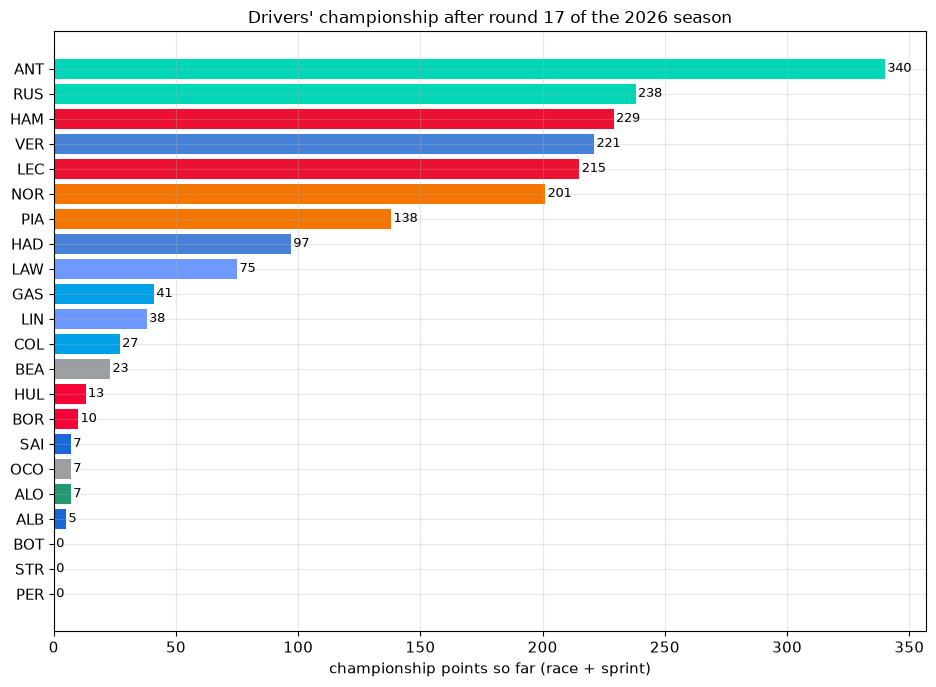

In [6]:
finished = data["status"].isin(["Finished", "Lapped"]) | data["status"].str.startswith("+").fillna(False)
print(f"drivers seen : {data['driver'].nunique()}")
print(f"teams        : {data['team'].nunique()}")
print(f"retirements  : {(~finished).mean():.0%} of all race starts")

# Team name -> color: the bundled data/team_colors.csv first (no downloads),
# falling back to the latest completed round's session results; either way
# the map is expanded with every historical name of each team - the season
# CSVs carry the name fastf1 used at collection time, which can differ from
# the current one within a single season (Alpine F1 Team -> Alpine,
# RB F1 Team -> Racing Bulls, ...)
TEAM_LINEAGES = (
    {"Red Bull", "Red Bull Racing"},
    {"Renault", "Alpine", "Alpine F1 Team"},
    {"Sauber", "Alfa Romeo", "Alfa Romeo Racing", "Kick Sauber", "Audi"},
    {"Toro Rosso", "AlphaTauri", "RB", "RB F1 Team", "Racing Bulls"},
    {"Force India", "Racing Point", "Aston Martin"},
    {"Cadillac", "Cadillac F1 Team"},
)


def expand_team_aliases(colors):
    # color map with every historical name of each mapped team added, so a
    # frame using either naming scheme finds its team's color
    expanded = dict(colors)
    for lineage in TEAM_LINEAGES:
        known = [name for name in lineage if name in colors]
        if not known:
            continue
        for name in lineage:
            expanded.setdefault(name, colors[known[0]])
    return expanded


def team_colors_for(year):
    colors = {}
    bundle = DATA_DIR / "team_colors.csv"
    if bundle.exists():
        table = pd.read_csv(bundle)
        rows = table[table["year"] == year]
        colors = {str(t): str(c) for t, c in zip(rows["team"], rows["color"])}
    if not colors:
        # live fallback; only well-formed hex values are accepted - fastf1
        # session results can carry glitched TeamColor cells
        year_schedule = fastf1.get_event_schedule(year, include_testing=False)
        for rn, _name in reversed(completed_rounds(year_schedule)):
            try:
                session = fastf1.get_session(year, rn, "R")
                session.load(laps=False, telemetry=False, weather=False, messages=False)
                colors = {t: "#" + c for t, c in
                          zip(session.results["TeamName"], session.results["TeamColor"])
                          if re.fullmatch(r"[0-9a-fA-F]{6}", str(c))}
                if colors:
                    break
            except Exception:
                continue
    return expand_team_aliases(colors)


TEAM_COLORS = team_colors_for(SEASON)

entrant = spec["entrant"]
current = features[(features["year"] == SEASON) & (features["round"] == last_round)]
current = current.sort_values(["points_so_far", spec["tiebreak"]])
color_by = current["team"] if CHAMPIONSHIP == "drivers" else current[entrant]
colors = [TEAM_COLORS.get(t, "#999999") for t in color_by]

fig, ax = plt.subplots(figsize=(9.5, 7))
ax.barh(np.arange(len(current)), current["points_so_far"], color=colors)
ax.set_yticks(np.arange(len(current)), current[entrant])
for y, v in enumerate(current["points_so_far"]):
    ax.text(v + 1, y, f"{v:g}", va="center", fontsize=9)
ax.set(xlabel="championship points so far (race + sprint)",
       title=f"{spec['label']} after round {last_round} of the {SEASON} season")
fig.tight_layout()
plt.show()


complete seasons in the training pool: 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025


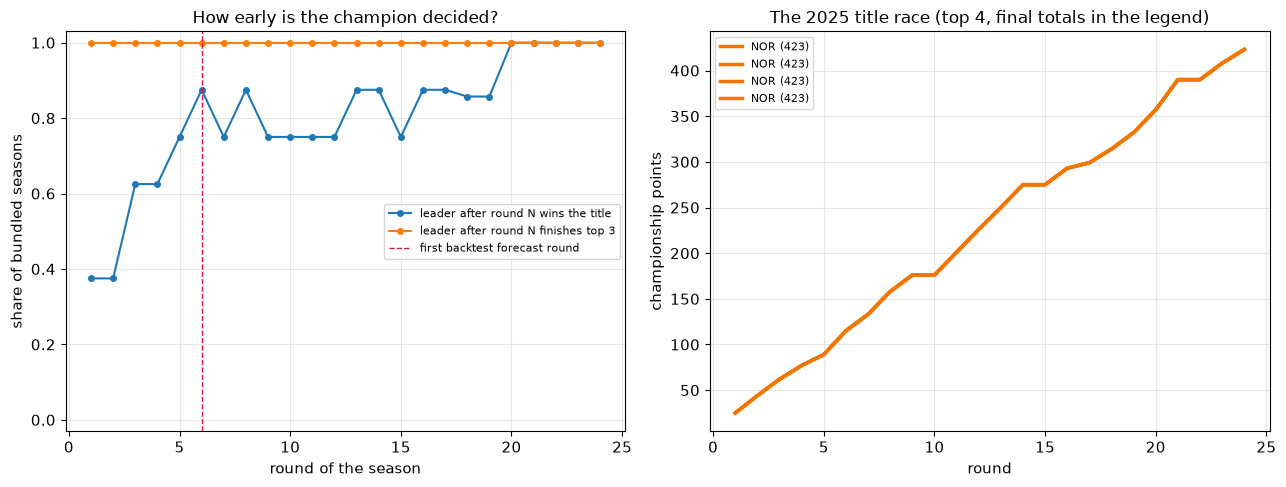

In [7]:
complete_rows = features[features["final"].notna()]
history_years = sorted(int(y) for y in complete_rows["year"].unique())
print(f"complete seasons in the training pool: {', '.join(map(str, history_years))}")

# how often does the points leader after round N end the season as champion?
max_round = int(complete_rows["round"].max())
leader_champ, leader_top3 = [], []
for r in range(1, max_round + 1):
    rows = complete_rows[complete_rows["round"] == r]
    if rows.empty:
        continue
    champ_hits, top3_hits = [], []
    for y in rows["year"].unique():
        snap = rows[rows["year"] == y]
        leader = snap.sort_values(["points_so_far", spec["tiebreak"]],
                                  ascending=[False, True]).iloc[0][entrant]
        final = snap.sort_values(["final", spec["tiebreak"]],
                                 ascending=[False, True])
        champ_hits.append(leader == final.iloc[0][entrant])
        top3_hits.append(leader in set(final.head(3)[entrant]))
    leader_champ.append((r, float(np.mean(champ_hits))))
    leader_top3.append((r, float(np.mean(top3_hits))))

story_year = history_years[-1]
story = complete_rows[complete_rows["year"] == story_year]
story_order = story.sort_values(["final", spec["tiebreak"]], ascending=[False, True])
story_top = list(story_order.head(4)[entrant])
story_colors = team_colors_for(story_year)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

rr = [r for r, _ in leader_champ]
axes[0].plot(rr, [v for _, v in leader_champ], marker="o", ms=4,
             label="leader after round N wins the title")
axes[0].plot(rr, [v for _, v in leader_top3], marker="o", ms=4,
             label="leader after round N finishes top 3")
axes[0].axvline(MIN_TRAIN_ROUNDS + 1, c="crimson", ls="--", lw=1,
                label="first backtest forecast round")
axes[0].set(xlabel="round of the season", ylabel="share of bundled seasons",
            ylim=(-0.03, 1.03), title="How early is the champion decided?")
axes[0].legend(loc="center right", fontsize=8)

for name in story_top:
    line = story[story[entrant] == name].sort_values("round")
    is_champion = name == story_top[0]
    team = line["team"].iloc[0] if CHAMPIONSHIP == "drivers" else name
    axes[1].plot(line["round"], line["points_so_far"],
                 color=story_colors.get(team, "#999999"),
                 lw=2.5 if is_champion else 1.5,
                 alpha=1.0 if is_champion else 0.75,
                 label=f"{name} ({line['final'].iloc[0]:g})")
axes[1].set(xlabel="round", ylabel="championship points",
            title=f"The {story_year} title race (top 4, final totals in the legend)")
axes[1].legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()


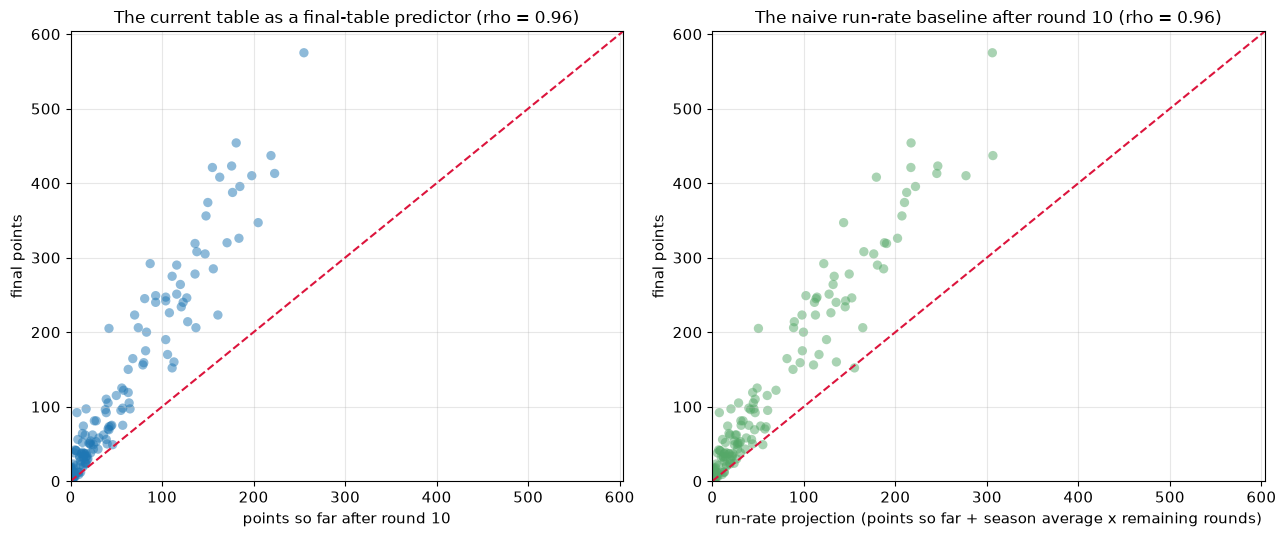

In [8]:
R = 10  # a mid-season snapshot round (every bundled complete season has one)
snap = complete_rows[complete_rows["round"] == R]
rho_now = snap["points_so_far"].corr(snap["final"], method="spearman")
rho_base = snap["points_rate_projection"].corr(snap["final"], method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
top = max(snap["final"].max(), snap["points_rate_projection"].max()) * 1.05
lim = [0, top]

axes[0].scatter(snap["points_so_far"], snap["final"], s=45, alpha=0.5, edgecolor="none")
axes[0].plot(lim, lim, ls="--", c="crimson")
axes[0].set(xlabel=f"points so far after round {R}", ylabel="final points",
            title=f"The current table as a final-table predictor (rho = {rho_now:.2f})")

axes[1].scatter(snap["points_rate_projection"], snap["final"], s=45, alpha=0.5,
                edgecolor="none", color="#55a868")
axes[1].plot(lim, lim, ls="--", c="crimson")
axes[1].set(xlabel="run-rate projection (points so far + season average x remaining rounds)",
            ylabel="final points",
            title=f"The naive run-rate baseline after round {R} (rho = {rho_base:.2f})")

for ax in axes:
    ax.set_xlim(lim)
    ax.set_ylim(lim)
fig.tight_layout()
plt.show()


## 4. Feature engineering - championship snapshots

Every training/prediction row is a **snapshot**: one entrant's championship state after one round of one season. The frame was built in section 2; here is what is in it.

| feature | meaning |
|---|---|
| `rounds_done` / `rounds_remaining` | rounds the entrant has scored in / rounds left in the season |
| `points_so_far` | championship points after this round (race + sprint) |
| `points_per_round` | season-average points per round |
| `points_rate_projection` | the naive run-rate forecast: `points_per_round x rounds_remaining` - handed to the trees as an explicit feature because trees cannot multiply two columns |
| `points_last3_rate` | points per round over the last 3 rounds (current form) |
| `standings_pos` / `gap_to_leader` / `leader_points` | position in the table and distance to the top |
| `finish_avg` / `finish_form3` / `best_finish` | average, recent and best finishing positions (drivers only) |
| `quali_delta_avg` / `quali_delta_form3` | average and recent one-lap pace vs pole |
| `wins` / `podiums` | season win and podium counts (wins: drivers only) |
| `dnf_count` / `dnf_rate` | retirements so far and per round |
| `team_points_so_far` / `team_points_per_round` / `team_points_last3_rate` / `team_finish_avg` / `team_dnf_rate` | the same state for the entrant's team (drivers only) |
| `team_id` / `driver_id` | the constructor / the driver's three-letter code, as categoricals |

The target, `final`, is the entrant's points at the end of that season - known only for complete seasons, so the rows of the season in progress carry `NaN` and never train anything.

Leakage protection is structural: a forecast for year *Y* as of round *R* trains only on seasons **before** *Y*, and only on snapshots at rounds **up to** *R* - the training distribution mirrors the live task, and no season is ever predicted with knowledge of its own ending (that is also why the backtest in section 6 is leave-one-season-out).


In [9]:
# the live forecasting input: the championship state at the last completed round
state_cols = [c for c in (
    [entrant] + (["team"] if CHAMPIONSHIP == "drivers" else [])
    + ["points_so_far", "standings_pos", "gap_to_leader", "points_per_round",
       "points_last3_rate", "points_rate_projection", "wins", "podiums",
       "dnf_count", "finish_avg"]
) if c in features.columns]
now_state = features[(features["year"] == SEASON) & (features["round"] == last_round)]
now_state = now_state.sort_values("standings_pos")
print(f"the championship state after round {last_round} (the live forecasting input):")
display(now_state[state_cols].head(10).reset_index(drop=True))

# and one entrant's rows across a complete season - every round is a
# separate training row whose target (`final`) is the season's outcome
story_champ = complete_rows[complete_rows["year"] == story_year].sort_values(
    ["final", spec["tiebreak"]], ascending=[False, True]).iloc[0][entrant]
example = complete_rows[(complete_rows["year"] == story_year)
                        & (complete_rows[entrant] == story_champ)].sort_values("round")
example_cols = [c for c in ["round", "event", "points_so_far", "points_per_round",
                            "points_rate_projection", "standings_pos", "final"]
                if c in example.columns]
print(f"\none entrant's snapshots across a complete season "
      f"({story_year} {story_champ} - `final` is constant, points accumulate):")
display(example[example_cols].head(8).reset_index(drop=True))


the championship state after round 17 (the live forecasting input):


,driver,team,points_so_far,standings_pos,gap_to_leader,points_per_round,points_last3_rate,points_rate_projection,wins,podiums,dnf_count,finish_avg
0,ANT,Mercedes,340.0,1.0,0.0,20.000000,16.000000,120.000000,8,14,1,3.470588
1,RUS,Mercedes,238.0,2.0,102.0,14.000000,9.000000,84.000000,3,8,3,6.823529
2,HAM,Ferrari,229.0,3.0,111.0,13.470588,12.666667,80.823529,1,6,1,5.176471
3,VER,Red Bull,221.0,4.0,119.0,13.000000,25.333333,78.000000,2,9,4,7.176471
4,LEC,Ferrari,215.0,5.0,125.0,12.647059,16.000000,75.882353,1,5,3,6.470588
5,NOR,McLaren,201.0,6.0,139.0,11.823529,5.000000,70.941176,2,5,4,7.705882
6,PIA,McLaren,138.0,7.0,202.0,8.117647,6.000000,48.705882,0,2,3,8.705882
7,HAD,Red Bull,97.0,8.0,243.0,6.928571,8.666667,41.571429,0,2,2,8.357143
8,LAW,RB F1 Team,75.0,9.0,265.0,4.411765,5.333333,26.470588,0,0,1,9.235294
9,GAS,Alpine F1 Team,41.0,10.0,299.0,2.411765,0.000000,14.470588,0,0,2,10.941176



one entrant's snapshots across a complete season (2025 NOR - `final` is constant, points accumulate):


,round,event,points_so_far,points_per_round,points_rate_projection,standings_pos,final
0,1,Australian Grand Prix,25.0,25.000000,575.0,1.0,423.0
1,2,Chinese Grand Prix,44.0,22.000000,484.0,1.0,423.0
2,3,Japanese Grand Prix,62.0,20.666667,434.0,1.0,423.0
3,4,Bahrain Grand Prix,77.0,19.250000,385.0,1.0,423.0
4,5,Saudi Arabian Grand Prix,89.0,17.800000,338.2,2.0,423.0
5,6,Miami Grand Prix,115.0,19.166667,345.0,2.0,423.0
6,7,Emilia Romagna Grand Prix,133.0,19.000000,323.0,2.0,423.0
7,8,Monaco Grand Prix,158.0,19.750000,316.0,2.0,423.0


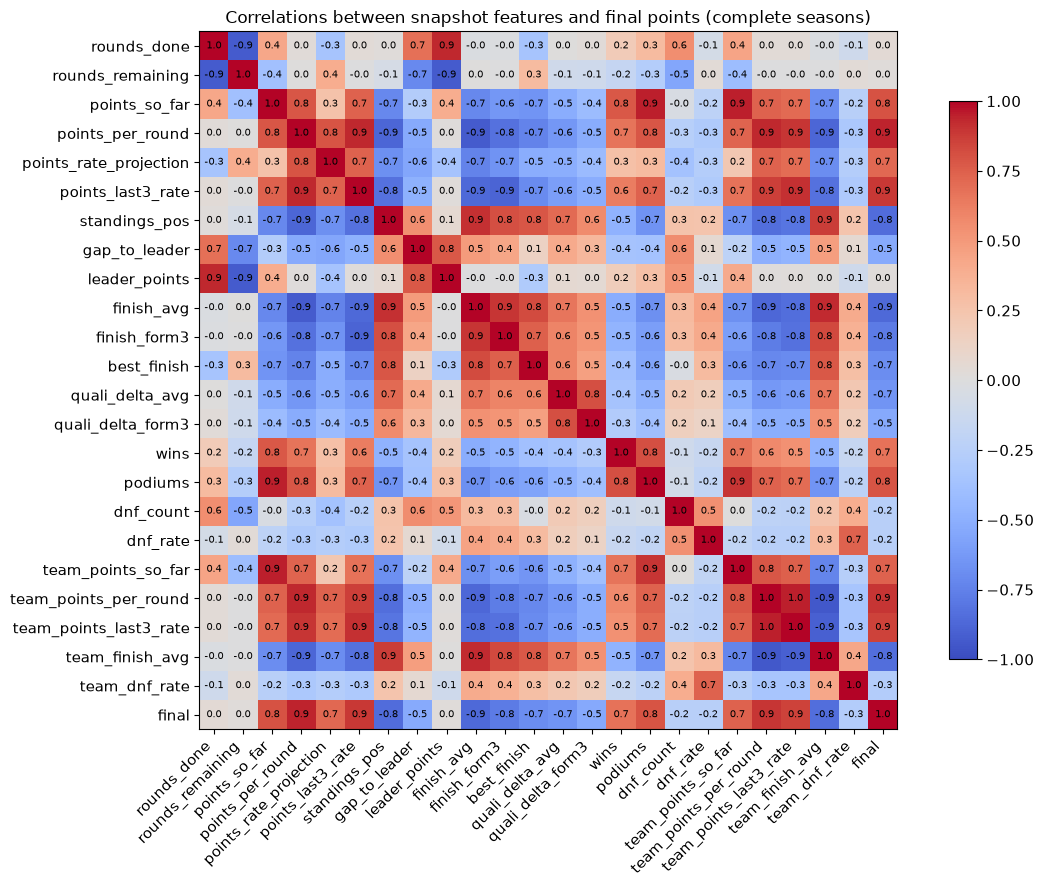

In [10]:
corr_cols = [f for f in spec["features"] if f not in ("team_id", "driver_id")] + ["final"]
corr = complete_rows[corr_cols].corr()

fig, ax = plt.subplots(figsize=(12, 9))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=45, ha="right")
ax.set_yticks(range(len(corr_cols)), corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.1f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, shrink=0.8)
ax.grid(False)
ax.set(title="Correlations between snapshot features and final points (complete seasons)")
fig.tight_layout()
plt.show()


## 5. The models

Two gradient-boosting models, same features, different targets:

- **remaining model** - predicts the *points still to be scored* (`final - points_so_far`); the projection is points so far + prediction, clamped at zero. This is the race notebook's gain-model idea transplanted to the championship: it anchors on the strongest prior (the current table) and learns only the correction, which keeps it honest late in the season when the run-rate is nearly exact.
- **direct model** - predicts the **absolute final points** straight from the snapshot, clamped below at the points already scored. More freedom to leapfrog the current table when pace and form say so - and more room to be wrong.

Both are compared against the naive **run-rate baseline** (current points + season-average per round x remaining rounds), and both use `HistGradientBoostingRegressor` (native missing-value and categorical handling) with absolute-error loss. Training frames with an all-`NaN` feature column are handled by dropping that column for the fit (`usable_features`) - sklearn's histogram booster cannot fit a column with no observed values.

With `MODEL_PROFILE = "optimized"`, a seeded random search over `TUNED_SEARCH_SPACE` runs before every fit; the cross-validation folds hold out whole *seasons* at a time (each fold predicted by a model trained on earlier seasons only), and a candidate must beat the fast hyperparameters by at least 5% relative MAE to be adopted. The final-prediction cell prints the hyperparameters each model ended up with.

Projections become a predicted table by ranking; ties break on current points, then the stable entrant key.


In [11]:
MODEL_PROFILES = ("fast", "optimized")

# fast      - fixed hyperparameters; quickest to run.
# optimized - per-fit search over TUNED_SEARCH_SPACE that minimizes
#             cross-validated MAE over leave-one-season-out folds.
FAST_PARAMS = {
    "loss": "absolute_error",
    "learning_rate": 0.08,
    "max_iter": 150,
    "max_leaf_nodes": 15,
    "min_samples_leaf": 20,
    "l2_regularization": 1.0,
}

TUNED_SEARCH_SPACE = {
    "learning_rate": [0.03, 0.06, 0.08, 0.12, 0.2],
    "max_iter": [100, 200, 400],
    "max_leaf_nodes": [3, 7, 15, 31],
    "min_samples_leaf": [5, 10, 20, 40],
    "l2_regularization": [0.0, 0.25, 1.0, 4.0],
}
TUNE_N_ITER = 20
TUNE_MAX_SPLITS = None
TUNE_MIN_IMPROVEMENT = 0.05
TUNE_STRIDE = 2
TUNE_RANDOM_STATE = 42


def usable_features(frame, feature_names):
    # feature_names minus any column that is entirely NaN in `frame` -
    # sklearn's Hist gradient boosting cannot fit a feature with no
    # observed values (the driver-id column can be all-unknown early, and
    # quali/race form is empty for a debut-only entrant set)
    matrix = frame[feature_names].to_numpy(dtype=float)
    return [name for name, col in zip(feature_names, matrix.T) if not np.isnan(col).all()]


def make_model(categorical_features, profile="fast", tuned_params=None):
    if profile not in MODEL_PROFILES:
        raise ValueError(f"unknown model profile: {profile!r}")
    params = dict(FAST_PARAMS)
    if profile == "optimized" and tuned_params:
        params.update(tuned_params)
    return HistGradientBoostingRegressor(
        categorical_features=categorical_features,
        random_state=42,
        **params,
    )


def tune_hyperparameters(X, y, rounds, categorical_features=None,
                         n_iter=TUNE_N_ITER, random_state=TUNE_RANDOM_STATE):
    # search TUNED_SEARCH_SPACE for the combination with the lowest
    # cross-validated MAE on one model's training set. The CV folds hold
    # out one entry of `rounds` at a time - the championship pipeline
    # passes the training SEASONS, so each fold is one season predicted
    # by a model trained on the earlier ones - and errors are pooled
    # across folds. The fast combination is always evaluated first and
    # ties keep it; a candidate must beat it by at least
    # TUNE_MIN_IMPROVEMENT relative MAE to be adopted (with so few folds
    # that margin stops the search chasing fold noise).
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)
    rounds = np.asarray(rounds)
    unique = np.unique(rounds)
    if TUNE_MAX_SPLITS is None:
        val_rounds = unique[1::TUNE_STRIDE]
    else:
        val_rounds = unique[-min(TUNE_MAX_SPLITS, len(unique) - 1):]
    if len(val_rounds) == 0:
        return None
    # a fold whose training share is all-NaN in some column would crash
    # HistGradientBoosting - zero those columns for the fit; a constant
    # column cannot be split on, so the model simply ignores that
    # feature in that fold
    fold_sets = []
    for r in val_rounds:
        X_train = X[rounds < r]
        all_nan = np.isnan(X_train).all(axis=0)
        if all_nan.any():
            X_train = X_train.copy()
            X_train[:, all_nan] = 0.0
        fold_sets.append((X_train, y[rounds < r], X[rounds == r], y[rounds == r]))

    keys = list(TUNED_SEARCH_SPACE)
    combos = list(product(*(TUNED_SEARCH_SPACE[key] for key in keys)))
    fast = tuple(FAST_PARAMS[key] for key in keys)
    rng = np.random.RandomState(random_state)
    sampled = [combo for combo in
               (combos[i] for i in rng.choice(len(combos), size=n_iter, replace=False))
               if combo != fast][:n_iter]
    candidates = [fast] + sampled

    def pooled_mae(combo):
        errors = []
        for X_train, y_train, X_val, y_val in fold_sets:
            model = HistGradientBoostingRegressor(
                categorical_features=categorical_features,
                random_state=random_state,
                loss="absolute_error",
                **dict(zip(keys, combo)),
            )
            model.fit(X_train, y_train)
            errors.append(np.abs(model.predict(X_val) - y_val))
        return float(np.concatenate(errors).mean())

    fast_mae = pooled_mae(fast)
    best_params = None
    best_mae = np.inf
    for combo in candidates:
        mae = fast_mae if combo == fast else pooled_mae(combo)
        if mae < best_mae:
            best_mae = mae
            best_params = dict(zip(keys, combo))
    if best_mae > fast_mae * (1 - TUNE_MIN_IMPROVEMENT):
        return None
    return best_params


def format_params(params):
    if not params:
        return ""
    return ", ".join(f"{key}={value}" for key, value in params.items())


def rank_corr(a, b):
    ra = pd.Series(a).rank().to_numpy()
    rb = pd.Series(b).rank().to_numpy()
    if np.std(ra) == 0 or np.std(rb) == 0:
        return np.nan
    return float(np.corrcoef(ra, rb)[0, 1])


def train_model(features, target_year, snapshot_round, mode="remaining",
                profile="fast", championship="drivers"):
    # fit one championship model on snapshots of every COMPLETE season
    # before target_year, at rounds up to snapshot_round - the training
    # distribution mirrors the live task: the forecast season never
    # contributes training rows, and later snapshots of past seasons are
    # excluded so early- and late-season forecasts train alike.
    # mode "remaining" learns the points still to be scored (final -
    # points so far); mode "direct" learns the absolute final points.
    spec = CHAMPIONSHIPS[championship]
    train = features[
        (features["year"] < target_year)
        & (features["round"] <= snapshot_round)
        & features["final"].notna()
    ]
    if train.empty:
        raise ValueError(f"no complete earlier season to train on for a {target_year} forecast")
    if mode == "remaining":
        target = (train["final"] - train["points_so_far"]).to_numpy(dtype=float)
    else:
        target = train["final"].to_numpy(dtype=float)
    used = usable_features(train, spec["features"])
    X = train[used].to_numpy(dtype=float)
    categorical = [used.index(c) for c in ("team_id", "driver_id") if c in used]
    tuned = None
    if profile == "optimized":
        # leave-one-season-out folds: the tuner's round array is the season year
        tuned = tune_hyperparameters(X, target, train["year"].to_numpy(),
                                      categorical_features=categorical)
    model = make_model(categorical, profile, tuned)
    model.fit(X, target)
    return model, train, used, tuned


def _rank_frame(rows, value, championship):
    # deterministic standings order for one projected column: sort by the
    # projection (desc), then current points (desc), then the stable
    # entrant key
    spec = CHAMPIONSHIPS[championship]
    ordered = rows.sort_values([value, "points_so_far", spec["tiebreak"]],
                               ascending=[False, False, True])
    ordered = ordered.copy()
    ordered["pred_pos"] = np.arange(1, len(ordered) + 1)
    return ordered.sort_values("pred_pos")


def predict_snapshot(model, features, target_year, snapshot_round, mode,
                      use_features, championship="drivers"):
    # projected final standings for one season as of one round. Remaining
    # model output is clamped at zero (points cannot be un-scored), direct
    # model output at the current points (a final total below what is
    # already scored is impossible); rank ties break on current points.
    rows = features[(features["year"] == target_year)
                    & (features["round"] == snapshot_round)].copy()
    pred = model.predict(rows[use_features].to_numpy(dtype=float))
    if mode == "remaining":
        rows["pred_final"] = rows["points_so_far"] + np.clip(pred, 0.0, None)
    else:
        rows["pred_final"] = np.maximum(pred, rows["points_so_far"])
    return _rank_frame(rows, "pred_final", championship)


def baseline_projection(features, target_year, snapshot_round, championship="drivers"):
    # the naive forecast every model is compared against: current points +
    # season-average points per round x remaining rounds (run-rate
    # extrapolation)
    rows = features[(features["year"] == target_year)
                    & (features["round"] == snapshot_round)].copy()
    rows["pred_final"] = rows["points_so_far"] + rows["points_per_round"] * rows["rounds_remaining"]
    return _rank_frame(rows, "pred_final", championship)


## 6. Backtest - leave-one-season-out

The round-based pipelines backtest within a season; the championship pipeline cannot - a mid-season forecast of 2026 has to be scored against 2026's final table, which only exists once. Instead every **complete bundled season** is forecast after each of its rounds (from the first round with `MIN_TRAIN_ROUNDS` completed rounds before it, up to but excluding the final round - as of the last round there is nothing left to forecast), and every one of those forecasts is trained only on **earlier complete seasons**, at snapshot rounds up to the forecast round. That is exactly how the live forecast is made, one season earlier.

Metrics per (season, round), for **both models and the run-rate baseline**:

- **final-points MAE** - mean absolute error of projected final points across the whole field.
- **champion** - whether the predicted P1 is the season's actual champion.
- **podium** - overlap between the predicted and actual top 3 (0-3).
- **rank corr** - Spearman correlation between the predicted and final tables.

The per-season summary also tracks the **first round at which the champion was picked correctly** - the practical "when does the model call the title?" question.


In [12]:
def backtest_records(features, min_train_rounds, profile="fast", championship="drivers"):
    # leave-one-season-out: every complete bundled season forecast after
    # each of its rounds (from the first round with min_train_rounds
    # completed rounds before it, up to but excluding the season's final
    # round - as of the final round there is nothing left to forecast),
    # each forecast trained only on complete seasons before it, at
    # snapshot rounds up to the forecast round. One record per
    # (season, round); the models train inside the loop, so this cell
    # takes a few minutes under the fast profile.
    spec = CHAMPIONSHIPS[championship]
    entrant = spec["entrant"]
    records = []
    tune_note = " (tuning hyperparameters)" if profile == "optimized" else ""
    model_names = ["remaining", "direct"]
    for year in sorted(int(y) for y in features["year"].unique()):
        rows_season = features[features["year"] == year]
        if rows_season["final"].isna().all():
            continue  # a season in progress has no final standings to score
        n_train = int(features.loc[(features["year"] < year)
                                   & features["final"].notna(), "year"].nunique())
        if n_train == 0:
            print(f"backtest {year}: no complete earlier season to train on, skipped")
            continue
        rounds_total = int(rows_season["round"].max())
        for rnd in range(min_train_rounds + 1, rounds_total):
            rows = features[(features["year"] == year) & (features["round"] == rnd)]
            event = str(rows["event"].iloc[0])
            print(f"backtest {year} round {rnd:>2}  {event}: training "
                  f"{' + '.join(model_names)} model{'s' if len(model_names) > 1 else ''}{tune_note}...")
            actual = rows.sort_values(["final", spec["tiebreak"]],
                                      ascending=[False, True])
            actual_top1 = str(actual.iloc[0][entrant])
            actual_top3 = set(actual.head(3)[entrant])
            rec = {"season": year, "round": rnd, "event": event,
                   "train_seasons": n_train}
            try:
                fitted = {}
                for mode in model_names:
                    model, _train, used, _tuned = train_model(
                        features, year, rnd, mode, profile, championship)
                    fitted[mode] = (model, used)
            except ValueError:
                continue
            for mode, (model, used) in fitted.items():
                pred = predict_snapshot(model, features, year, rnd, mode, used, championship)
                top1 = str(pred.iloc[0][entrant])
                rec[f"{mode}_mae"] = float((pred["pred_final"] - pred["final"]).abs().mean())
                rec[f"{mode}_champion"] = int(top1 == actual_top1)
                rec[f"{mode}_podium"] = len(set(pred.head(3)[entrant]) & actual_top3)
                rec[f"{mode}_corr"] = rank_corr(pred["pred_pos"], -pred["final"])
                rec[f"{mode}_top1"] = top1
            base = baseline_projection(features, year, rnd, championship)
            base_top1 = str(base.iloc[0][entrant])
            rec["baseline_mae"] = float((base["pred_final"] - base["final"]).abs().mean())
            rec["baseline_champion"] = int(base_top1 == actual_top1)
            rec["baseline_podium"] = len(set(base.head(3)[entrant]) & actual_top3)
            rec["baseline_corr"] = rank_corr(base["pred_pos"], -base["final"])
            rec["baseline_top1"] = base_top1
            rec["actual_top1"] = actual_top1
            records.append(rec)
    return records


In [13]:
def _first_correct(records, season, field):
    for rec in records:
        if rec["season"] == season and rec.get(field) == 1:
            return int(rec["round"])
    return None


def _rate(records, field, season=None):
    values = [rec[field] for rec in records
              if field in rec and (season is None or rec["season"] == season)
              and pd.notna(rec.get(field))]
    return float(np.mean(values)) if values else np.nan


def backtest_report(records):
    print(f"\n=== Rolling backtest: remaining-points model vs direct model vs run-rate baseline ===")
    print("leave-one-season-out: every complete bundled season forecast after each round,")
    print("each forecast trained only on earlier complete seasons (the final round is skipped -")
    print("nothing is left to forecast as of the season's last round)")
    if not records:
        print("not enough completed seasons for a backtest yet")
        return
    seasons = sorted({rec["season"] for rec in records})
    print(f"\n{'season':>6} {'fcsts':>5}  {'first correct round':>19}  "
          f"{'champion hit rate':>25}  {'final-points MAE':>25}")
    for season in seasons:
        recs = [rec for rec in records if rec["season"] == season]
        firsts = "/".join(str(_first_correct(records, season, f"{m}_champion"))
                          for m in ("remaining", "direct", "baseline"))
        hits = "/".join(f"{100 * _rate(recs, f'{m}_champion'):.0f}%"
                        for m in ("remaining", "direct", "baseline"))
        maes = "/".join(f"{_rate(recs, f'{m}_mae'):.1f}"
                        for m in ("remaining", "direct", "baseline"))
        print(f"{season:>6} {len(recs):>5}  {firsts:>19}  {hits:>25}  {maes:>25}")
    n = len(records)
    print(f"\nMean over {n} forecasts ({len(seasons)} seasons):")
    print(f"{'':>26}{'remaining':>11}{'direct':>9}{'baseline':>9}")
    print(f"{'champion hit rate':<26}"
          f"{100 * _rate(records, 'remaining_champion'):>10.0f}%"
          f"{100 * _rate(records, 'direct_champion'):>10.0f}%"
          f"{100 * _rate(records, 'baseline_champion'):>10.0f}%")
    print(f"{'top-3 standings overlap':<26}"
          f"{_rate(records, 'remaining_podium'):>10.2f}"
          f"{_rate(records, 'direct_podium'):>10.2f}"
          f"{_rate(records, 'baseline_podium'):>10.2f}")
    print(f"{'final-points MAE':<26}"
          f"{_rate(records, 'remaining_mae'):>10.2f}"
          f"{_rate(records, 'direct_mae'):>10.2f}"
          f"{_rate(records, 'baseline_mae'):>10.2f}")
    line = f"{'rank correlation':<26}"
    for field in ("remaining_corr", "direct_corr", "baseline_corr"):
        rate = _rate(records, field)
        line += f"{rate:>10.2f}" if pd.notna(rate) else f"{'-':>10}"
    print(line)


records = backtest_records(features, MIN_TRAIN_ROUNDS, MODEL_PROFILE, CHAMPIONSHIP)
bt = pd.DataFrame(records)
display(bt.round(2))
print()
backtest_report(records)


backtest 2018: no complete earlier season to train on, skipped
backtest 2019 round  6  Monaco Grand Prix: training remaining + direct models...


backtest 2019 round  7  Canadian Grand Prix: training remaining + direct models...


backtest 2019 round  8  French Grand Prix: training remaining + direct models...


backtest 2019 round  9  Austrian Grand Prix: training remaining + direct models...


backtest 2019 round 10  British Grand Prix: training remaining + direct models...


...

backtest 2025 round 21  São Paulo Grand Prix: training remaining + direct models...


backtest 2025 round 22  Las Vegas Grand Prix: training remaining + direct models...


backtest 2025 round 23  Qatar Grand Prix: training remaining + direct models...


,season,round,event,train_seasons,remaining_mae,remaining_champion,remaining_podium,remaining_corr,remaining_top1,direct_mae,direct_champion,direct_podium,direct_corr,direct_top1,baseline_mae,baseline_champion,baseline_podium,baseline_corr,baseline_top1,actual_top1
0,2019,6,Monaco Grand Prix,1,26.69,1,2,0.77,HAM,25.99,1,2,0.76,HAM,25.50,1,2,0.89,HAM,HAM
1,2019,7,Canadian Grand Prix,1,26.21,1,2,0.74,HAM,30.71,1,2,0.83,HAM,24.00,1,2,0.90,HAM,HAM
2,2019,8,French Grand Prix,1,25.01,1,2,0.78,HAM,30.81,1,2,0.84,HAM,22.94,1,2,0.89,HAM,HAM
3,2019,9,Austrian Grand Prix,1,29.48,1,2,0.84,HAM,24.69,1,2,0.85,HAM,19.67,1,3,0.91,HAM,HAM
4,2019,10,British Grand Prix,1,28.43,1,3,0.86,HAM,46.03,1,2,0.77,HAM,18.00,1,3,0.92,HAM,HAM
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
105,2025,19,United States Grand Prix,7,12.42,0,3,0.92,PIA,12.14,0,3,0.91,VER,10.50,0,3,0.95,PIA,NOR
106,2025,20,Mexico City Grand Prix,7,11.46,1,3,0.96,NOR,15.86,0,3,0.94,PIA,10.00,1,3,0.97,NOR,NOR
107,2025,21,São Paulo Grand Prix,7,8.26,1,3,0.97,NOR,9.79,1,3,0.94,NOR,7.97,1,3,0.97,NOR,NOR
108,2025,22,Las Vegas Grand Prix,7,6.60,1,3,0.98,NOR,10.62,0,3,0.97,PIA,5.28,1,3,0.98,NOR,NOR




=== Rolling backtest: remaining-points model vs direct model vs run-rate baseline ===
leave-one-season-out: every complete bundled season forecast after each round,
each forecast trained only on earlier complete seasons (the final round is skipped -
nothing is left to forecast as of the season's last round)

season fcsts  first correct round          champion hit rate           final-points MAE
  2019    15                6/6/6             100%/100%/100%             20.0/35.8/13.6
  2020    11                6/6/6              100%/91%/100%             29.3/31.8/10.5
  2021    16                7/6/6                 38%/6%/81%             13.4/19.7/12.4
  2022    16                6/6/6             100%/100%/100%             19.2/29.6/11.2
  2023    16                6/6/6             100%/100%/100%             18.6/29.3/19.2
  2024    18                6/6/6             100%/100%/100%             24.7/30.6/21.6
  2025    18             20/12/20                22%/22%/22%            

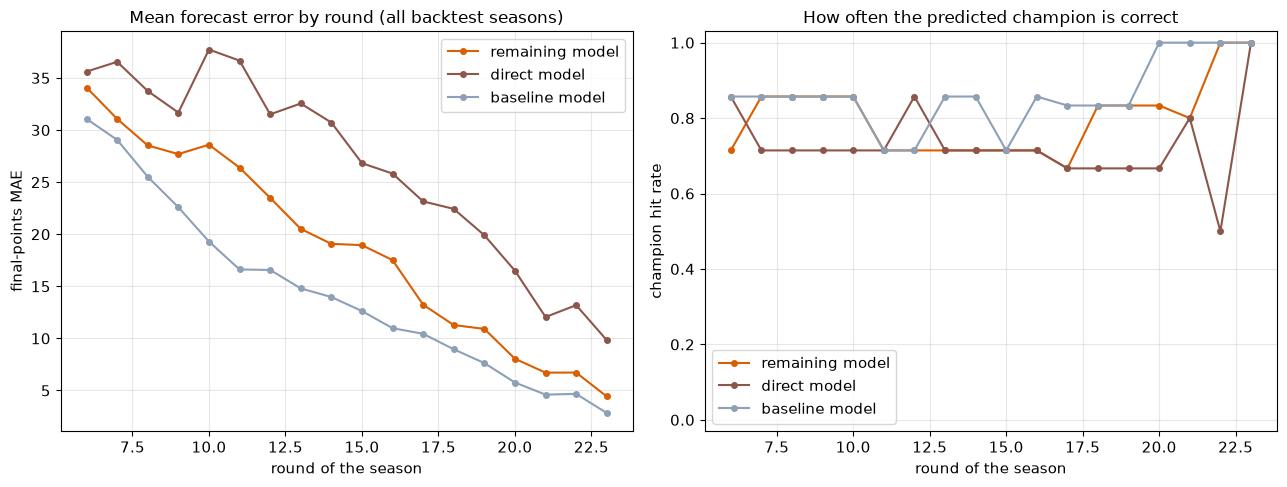

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

palette = (("remaining", "#d95f02"), ("direct", "#8c564b"), ("baseline", "#8ea0b5"))
for model, color in palette:
    means = bt.groupby("round")[f"{model}_mae"].mean()
    axes[0].plot(means.index, means.values, marker="o", ms=4, label=f"{model} model", color=color)
axes[0].set(xlabel="round of the season", ylabel="final-points MAE",
            title="Mean forecast error by round (all backtest seasons)")
axes[0].legend()

for model, color in palette:
    means = bt.groupby("round")[f"{model}_champion"].mean()
    axes[1].plot(means.index, means.values, marker="o", ms=4, label=f"{model} model", color=color)
axes[1].set(xlabel="round of the season", ylabel="champion hit rate",
            ylim=(-0.03, 1.03), title="How often the predicted champion is correct")
axes[1].legend()

fig.tight_layout()
plt.show()


## 7. Predicting the final standings

The notebook projects the table as of the **last completed round** (or `SNAPSHOT_ROUND` from the setup cell - any completed round, for a retro-forecast). Two modes:

- **live** - the season is still in progress: a genuine forecast of the final table, champion pick and title margins.
- **post** - the season is over: the same projection is scored against the actual final standings (the last-round snapshot is the converged table; pick an earlier round to see a real forecast of a decided season).

In the result table, `rem` and `direct` are the predicted positions from the two models, `now` the current points, `rem pts` / `dir pts` the projected final totals and `base pts` the run-rate baseline's projection; in post mode `final` is the actual total and `err *` the models' errors.


In [15]:
completed = sorted(int(r) for r in data["round"].unique())
if not completed:
    raise SystemExit(f"no completed rounds found for the {SEASON} season")

if SNAPSHOT_ROUND is None:
    snapshot = completed[-1]
else:
    snapshot = int(SNAPSHOT_ROUND)
    if snapshot not in completed:
        raise SystemExit(f"round {snapshot} has not been completed yet "
                         f"(last completed round: {completed[-1]})")
rounds_before = sum(1 for r in completed if r < snapshot)
if rounds_before < MIN_TRAIN_ROUNDS:
    raise SystemExit(f"a forecast as of round {snapshot} has only {rounds_before} completed "
                     f"rounds before it - a championship forecast needs at least {MIN_TRAIN_ROUNDS}; "
                     f"pick a later round or lower the minimum")

event_name = str(data.loc[data["round"] == snapshot, "event"].iloc[0])
rounds_total = int(schedule["RoundNumber"].max())
mode = "post" if complete else "live"

if mode == "live":
    print(f"season in progress: {snapshot} of {rounds_total} rounds completed, "
          f"{rounds_total - snapshot} to go")
else:
    print(f"season complete ({rounds_total} rounds)")
    if snapshot == rounds_total:
        print("as of the final round there is nothing left to forecast - this is the")
        print("converged state; pick an earlier SNAPSHOT_ROUND for a retro-forecast")
print(f"\nForecast: final {SEASON} {spec['label'].lower()} standings "
      f"as of round {snapshot} - {event_name} ({mode} mode)")


season in progress: 17 of 23 rounds completed, 6 to go

Forecast: final 2026 drivers' championship standings as of round 17 - Singapore Grand Prix (live mode)


In [16]:
tune_note = " (tuning hyperparameters)" if MODEL_PROFILE == "optimized" else ""

print(f"training final remaining-points model{tune_note}...")
remaining_model, train_set, remaining_used, remaining_params = train_model(
    features, SEASON, snapshot, "remaining", MODEL_PROFILE, CHAMPIONSHIP)
remaining = predict_snapshot(remaining_model, features, SEASON, snapshot,
                             "remaining", remaining_used, CHAMPIONSHIP)

print(f"training final direct model{tune_note}...")
direct_model, _direct_train, direct_used, direct_params = train_model(
    features, SEASON, snapshot, "direct", MODEL_PROFILE, CHAMPIONSHIP)
direct = predict_snapshot(direct_model, features, SEASON, snapshot,
                          "direct", direct_used, CHAMPIONSHIP)

baseline = baseline_projection(features, SEASON, snapshot, CHAMPIONSHIP)

entrant = spec["entrant"]
direct_key = direct.set_index(entrant)
result = pd.DataFrame({
    "rem": remaining["pred_pos"].to_numpy(),
    "direct": remaining[entrant].map(direct_key["pred_pos"]).astype(int).to_numpy(),
    entrant: remaining[entrant].to_numpy(),
})
if CHAMPIONSHIP == "drivers":
    result["team"] = remaining["team"].to_numpy()
result["now"] = remaining["points_so_far"].to_numpy()
result["rem pts"] = remaining["pred_final"].to_numpy()
result["dir pts"] = remaining[entrant].map(direct_key["pred_final"]).to_numpy()
result["base pts"] = remaining[entrant].map(
    baseline.set_index(entrant)["pred_final"]).to_numpy()
if mode == "post":
    result["final"] = remaining["final"].to_numpy()
    result["err rem"] = result["rem pts"] - result["final"]
    result["err dir"] = result["dir pts"] - result["final"]

points_fmt = lambda v: f"{v:g}"
top = remaining.iloc[0]
second = remaining.iloc[1] if len(remaining) > 1 else None
margin = (f", margin {top['pred_final'] - second['pred_final']:+g} over {second[entrant]}"
          if second is not None else "")
print(f"\nPredicted champion - remaining model: {top[entrant]} "
      f"({points_fmt(top['pred_final'])} pts{margin})")
top_direct = direct.iloc[0]
print(f"Predicted champion - direct model:    {top_direct[entrant]} "
      f"({points_fmt(top_direct['pred_final'])} pts)")
top_base = baseline.iloc[0]
print(f"Baseline projection champion:          {top_base[entrant]} "
      f"({points_fmt(top_base['pred_final'])} pts)")
if mode == "post":
    actual_rows = features[(features["year"] == SEASON) & (features["round"] == snapshot)]
    actual_champion = actual_rows.sort_values(
        ["final", spec["tiebreak"]], ascending=[False, True]).iloc[0]
    verdicts = [
        f"remaining model {'hit' if top[entrant] == actual_champion[entrant] else 'miss'}",
        f"direct model {'hit' if top_direct[entrant] == actual_champion[entrant] else 'miss'}",
        f"baseline {'hit' if top_base[entrant] == actual_champion[entrant] else 'miss'}",
    ]
    print(f"Actual champion:                       {actual_champion[entrant]} "
          f"({points_fmt(actual_champion['final'])} pts) - {'; '.join(verdicts)}")
if MODEL_PROFILE == "optimized":
    untuned = "fast defaults (no clearly better combination found)"
    print(f"\nTuned hyperparameters (remaining model): "
          f"{format_params(remaining_params) or untuned}")
    print(f"Tuned hyperparameters (direct model):   "
          f"{format_params(direct_params) or untuned}")
result


training final remaining-points model...


training final direct model...



Predicted champion - remaining model: ANT (438.062 pts, margin +98.2189 over RUS)
Predicted champion - direct model:    ANT (350.639 pts)
Baseline projection champion:          ANT (460 pts)


,rem,direct,driver,team,now,rem pts,dir pts,base pts
0,1,1,ANT,Mercedes,340.0,438.061518,350.639299,460.000000
1,2,3,RUS,Mercedes,238.0,339.842663,332.747396,322.000000
2,3,4,VER,Red Bull,221.0,334.680203,316.181238,299.000000
3,4,2,HAM,Ferrari,229.0,306.089484,342.622128,309.823529
4,5,5,LEC,Ferrari,215.0,293.206822,272.561002,290.882353
5,6,7,NOR,McLaren,201.0,275.263752,228.676050,271.941176
6,7,6,PIA,McLaren,138.0,199.482686,235.830528,186.705882
7,8,8,HAD,Red Bull,97.0,134.653825,183.243121,138.571429
8,9,9,LAW,RB F1 Team,75.0,89.943859,75.000000,101.470588
9,10,11,GAS,Alpine F1 Team,41.0,52.146759,41.000000,55.470588


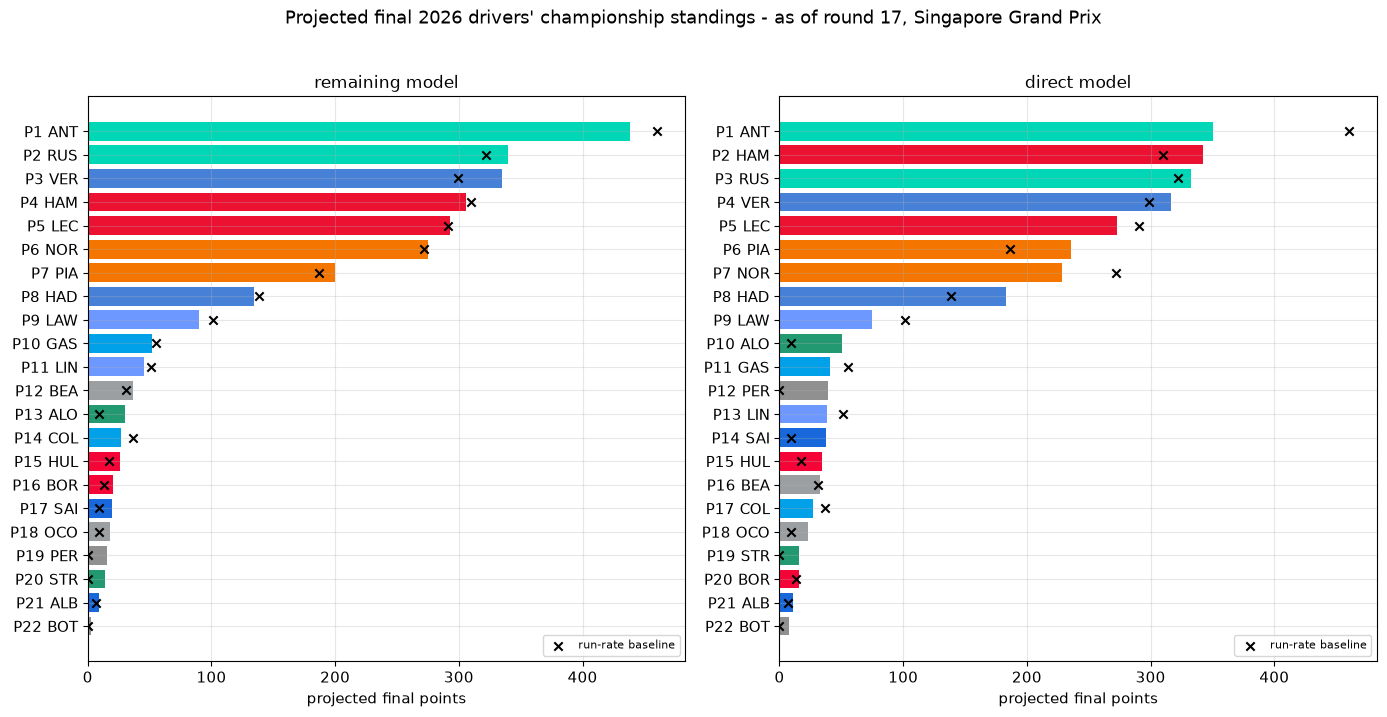

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, pred, name in ((axes[0], remaining, "remaining model"),
                      (axes[1], direct, "direct model")):
    ordered = pred.sort_values("pred_pos")
    y = np.arange(len(ordered))
    if CHAMPIONSHIP == "drivers":
        colors = [TEAM_COLORS.get(t, "#999999") for t in ordered["team"]]
    else:
        colors = [TEAM_COLORS.get(t, "#999999") for t in ordered[entrant]]
    ax.barh(y, ordered["pred_final"], color=colors)
    ax.scatter(ordered[entrant].map(baseline.set_index(entrant)["pred_final"]), y,
               marker="x", color="black", zorder=3, label="run-rate baseline")
    if mode == "post":
        ax.scatter(ordered["final"], y, marker="D", color="crimson", zorder=3,
                   label="actual final")
    ax.set_yticks(y, [f"P{p} {n}" for p, n in zip(ordered["pred_pos"], ordered[entrant])])
    ax.invert_yaxis()
    ax.set(xlabel="projected final points", title=name)
    ax.legend(loc="lower right", fontsize=8)
fig.suptitle(f"Projected final {SEASON} {spec['label'].lower()} standings - "
             f"as of round {snapshot}, {event_name}", y=1.02)
fig.tight_layout()
plt.show()


In [18]:
if mode == "post":
    fig, axes = plt.subplots(1, 2, figsize=(13, 6.5), sharex=True, sharey=True)
    for ax, pred, name in ((axes[0], remaining, "remaining model"),
                           (axes[1], direct, "direct model")):
        ax.scatter(pred["pred_final"], pred["final"], s=70, alpha=0.75)
        for _, row in pred.iterrows():
            ax.annotate(row[entrant], (row["pred_final"], row["final"]),
                        xytext=(5, 4), textcoords="offset points", fontsize=8)
        lim = [0, pred["final"].max() * 1.05]
        ax.plot(lim, lim, ls="--", c="crimson", label="perfect prediction")
        ax.set(xlabel="projected final points", ylabel="actual final points", title=name)
        ax.legend(loc="lower right")
    fig.suptitle(f"{SEASON} final {spec['label'].lower()} standings - "
                 f"projected vs actual", y=1.02)
    fig.tight_layout()
    plt.show()
else:
    print("the season is still in progress - the actual final table is unknown;")
    print("re-run once the season is over to see the scored comparison")


the season is still in progress - the actual final table is unknown;
re-run once the season is over to see the scored comparison


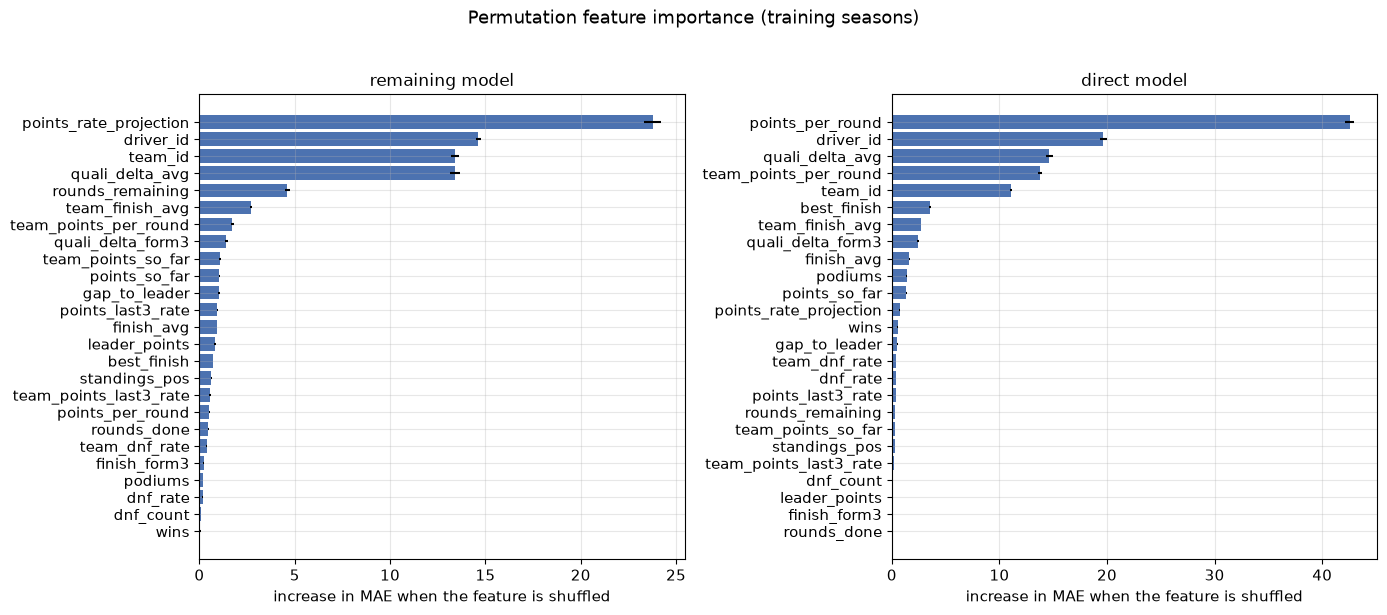

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
model_axes = (
    (axes[0], remaining_model, "remaining model", remaining_used,
     (train_set["final"] - train_set["points_so_far"]).to_numpy(dtype=float)),
    (axes[1], direct_model, "direct model", direct_used,
     train_set["final"].to_numpy(dtype=float)),
)
for ax, model, name, used, target_y in model_axes:
    imp = permutation_importance(
        model,
        train_set[used].to_numpy(dtype=float),
        target_y,
        scoring="neg_mean_absolute_error",
        n_repeats=5,
        random_state=42,
    )
    order = np.argsort(imp.importances_mean)
    ax.barh(np.array(used)[order], imp.importances_mean[order],
            xerr=imp.importances_std[order], color="#4c72b0")
    ax.set(xlabel="increase in MAE when the feature is shuffled", title=name)
fig.suptitle("Permutation feature importance (training seasons)", y=1.02)
fig.tight_layout()
plt.show()


## 8. Takeaways & next steps

- The run-rate baseline is deceptively strong: over this pool it keeps the best average final-points MAE and champion hit rate of the three - extrapolating the current table is nearly exact late in a season. The models track it closely, and the interesting part is where they disagree: in the 2025 backtest the direct model first picked the eventual champion at round 12, eight rounds before the remaining model and the baseline caught on.
- The remaining model's anchor keeps it calibrated - it deviates from the current table only when form, reliability and pace features justify it, which is why it rarely embarrasses itself early and converges to the baseline late.
- The backtest answers "when is the title called?": in five of the seven backtest seasons every method already had the eventual champion right at the first forecast round - the holdouts are the genuinely close fights (2021, 2025), which is exactly where a forecast is worth having. The hit-rate-by-round chart shows the climb, and the first-correct-round column of the per-season table gives each method's earliest correct call per season.
- Cross-season training is what makes a mid-season forecast possible at all: within a single season there is no target until the season is over. The price is that the models know nothing about a season's rules changes or car regs beyond what the features carry.
- Every projection uses only standings information through the snapshot round, so this is exactly the pipeline you could run on a Monday morning after a race: re-run the notebook and get the projected final table.

Ideas to extend:

- **Season weighting**: let older training seasons count less (cars, rules and points schemes drift across eras).
- **Calendar-aware pace**: rounds remaining split by circuit type, so a pace-heavy run-in can favour a different team than the raw count suggests.
- **Team-mate deltas**: title fights are often intra-team; head-to-head features could sharpen gaps.
- **Uncertainty**: quantile regression for title probabilities and interval forecasts instead of point projections.
- **Momentum**: features for mid-season seat swaps and driver changes, which currently break the entrant identity's continuity.
